In [1]:
from google.colab import files

uploaded = files.upload()

Saving student-mat.csv to student-mat.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('student-mat.csv', sep=';')

# Display first 5 rows
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Remove duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

# 3. Inspect dataset shape
print("\nDataset Shape:", df.shape)

# 4. Check data types
print("\nDataset Data Types:")
print(df.dtypes)

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Duplicate Records: 0

Dataset Shape: (395, 33)

Dataset Data Types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          obj

1. Missing Values Check

The dataset was checked for missing values using isnull().sum(). No missing values were found in any column.

2. Duplicate Records Removal

Duplicate records were checked using duplicated().sum(). No duplicate records were found. Therefore, no rows were removed.

3. Dataset Shape

The dataset contains 395 rows and 33 columns, representing student records and their attributes.

4. Data Types Inspection

The dataset contains numerical and categorical columns. Numerical columns use integer data types, while categorical columns use object data types.


In [6]:

# 1. Average Final Grade (G3)
average_grade = df['G3'].mean()

print("1. Average Final Grade:", round(average_grade, 2))


# 2. Students Scoring Above 15
students_above_15 = (df['G3'] > 15).sum()

print("\n2. Students Scoring Above 15:", students_above_15)


# 3. Correlation Between Study Time and Performance
correlation = df['studytime'].corr(df['G3'])

print("\n3. Study Time vs Final Grade Correlation:", round(correlation, 3))


# 4. Gender-wise Average Performance
gender_performance = df.groupby('sex')['G3'].mean()

print("\n4. Gender-wise Average Performance:")
print(gender_performance)


1. Average Final Grade: 10.42

2. Students Scoring Above 15: 40

3. Study Time vs Final Grade Correlation: 0.098

4. Gender-wise Average Performance:
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64


### Analysis Results

**1. Average Final Grade (G3)**

The average final grade of students was calculated using the G3 column. The average score is 10.42 out of 20, representing the overall academic performance of students.

**2. Students Scoring Above 15**

A total of 40 students scored above 15 marks in their final examination. These students achieved relatively high academic performance.

**3. Study Time vs Performance**

The correlation between study time and final grades was calculated to understand the relationship between students' study habits and academic performance.

**4. Gender-wise Average Performance**

The average final grades of male and female students were calculated separately to compare their academic performance.

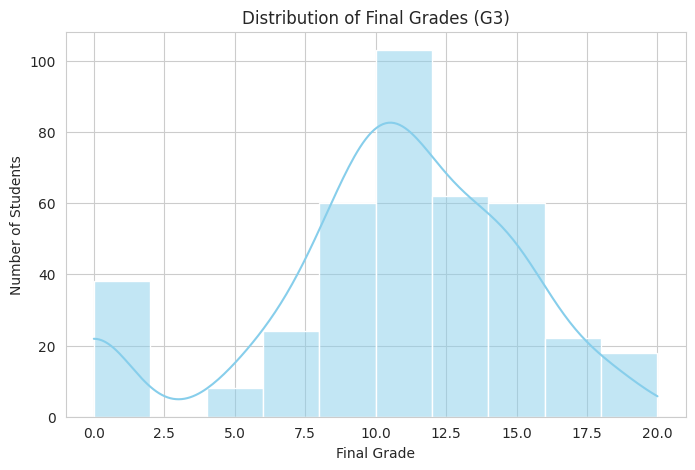

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# 1. Histogram of Grades
plt.figure(figsize=(8, 5))
sns.histplot(df['G3'], bins=10, kde=True, color='skyblue')

plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.show()





1. Histogram of Grades

The histogram shows the distribution of students' final grades (G3). It helps identify how student marks are distributed and which grade ranges are more common.

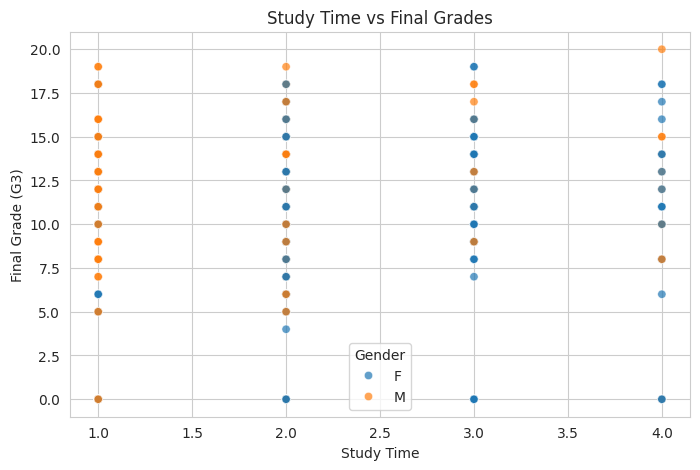

In [10]:
# 2. Scatterplot: Study Time vs Final Grades
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='studytime',
    y='G3',
    hue='sex',
    alpha=0.7
)

plt.title("Study Time vs Final Grades")
plt.xlabel("Study Time")
plt.ylabel("Final Grade (G3)")
plt.legend(title="Gender")
plt.show()




2. Scatterplot: Study Time vs Final Grades

The scatterplot represents the relationship between study time and final grades. Each point represents a student's study time and final grade. The graph helps identify patterns between study habits and academic performance.

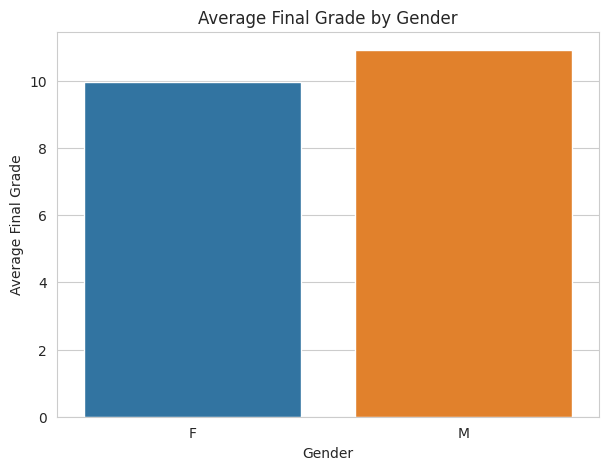

In [11]:
# 3. Bar Chart: Male vs Female Average Score
gender_avg = df.groupby('sex')['G3'].mean().reset_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    data=gender_avg,
    x='sex',
    y='G3',
    hue='sex',
    legend=False
)

plt.title("Average Final Grade by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Final Grade")
plt.show()


3. Bar Chart: Male vs Female Average Score

The bar chart compares the average final grades of male and female students. The analysis shows that male students have an average score of approximately 10.91, while female students have an average score of approximately 9.97.